Q1. Implement the de Waard-Milliams corrosion rate model with unit tests

The de Waard–Milliams model is used to estimate the corrosion rate of carbon steel exposed to carbon dioxide (CO₂)-containing environments. Temperature, CO₂ partial pressure, fluid chemistry and protective corrosion films influence the predicted corrosion rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import unittest

def de_waard_milliams_rate(
    temperature_c,
    co2_partial_pressure_bar,
    pH=5.0,
    film_flow_factor=1.0
):
    """Simplified CO2 corrosion estimate in mm/year."""

    T = np.asarray(temperature_c, dtype=float)
    P = np.asarray(co2_partial_pressure_bar, dtype=float)
    ph = np.asarray(pH, dtype=float)
    factor = np.asarray(film_flow_factor, dtype=float)

    if any(np.any(~np.isfinite(x)) for x in (T, P, ph, factor)):
        raise ValueError("Inputs must be finite.")

    if np.any(T <= -273.15):
        raise ValueError("Temperature must be above absolute zero.")

    if np.any(P <= 0):
        raise ValueError("CO2 partial pressure must be positive.")

    if np.any((ph < 3) | (ph > 7)):
        raise ValueError("pH must be between 3 and 7.")

    if np.any(factor <= 0):
        raise ValueError("Correction factor must be positive.")

    T_kelvin = T + 273.15

    temperature_factor = np.exp(
        1800 * (1 / 333.15 - 1 / T_kelvin)
    )

    co2_factor = np.sqrt(P)

    ph_factor = np.clip(
        10 ** (5 - ph), 0.1, 100
    ) ** 0.15

    calibration_factor = 0.1

    rate = (
        calibration_factor
        * temperature_factor
        * co2_factor
        * ph_factor
        * factor
    )

    return np.maximum(rate, 0.0)


# Unit tests
class TestCorrosionModel(unittest.TestCase):

    def test_positive_rate(self):
        self.assertGreater(
            float(de_waard_milliams_rate(60, 2, 5)), 0
        )

    def test_co2_effect(self):
        self.assertGreater(
            float(de_waard_milliams_rate(60, 4, 5)),
            float(de_waard_milliams_rate(60, 1, 5))
        )

    def test_temperature_effect(self):
        self.assertGreater(
            float(de_waard_milliams_rate(70, 2, 5)),
            float(de_waard_milliams_rate(30, 2, 5))
        )

    def test_invalid_co2(self):
        with self.assertRaises(ValueError):
            de_waard_milliams_rate(60, 0, 5)

    def test_invalid_ph(self):
        with self.assertRaises(ValueError):
            de_waard_milliams_rate(60, 2, 8)

    def test_array_input(self):
        rates = de_waard_milliams_rate(
            np.array([40, 60]),
            np.array([1, 2]),
            5
        )
        self.assertEqual(rates.shape, (2,))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(
    TestCorrosionModel
)

result = unittest.TextTestRunner(verbosity=2).run(suite)

assert result.wasSuccessful()

test_array_input (__main__.TestCorrosionModel.test_array_input) ... ok
test_co2_effect (__main__.TestCorrosionModel.test_co2_effect) ... ok
test_invalid_co2 (__main__.TestCorrosionModel.test_invalid_co2) ... ok
test_invalid_ph (__main__.TestCorrosionModel.test_invalid_ph) ... ok
test_positive_rate (__main__.TestCorrosionModel.test_positive_rate) ... ok
test_temperature_effect (__main__.TestCorrosionModel.test_temperature_effect) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.013s

OK


Q2. Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field

Supervisory Control and Data Acquisition (SCADA) systems collect operational measurements from industrial equipment. For this exercise, a synthetic dataset is generated for six subsea jumpers over ten years, from 1 January 2016 to 31 December 2025, at hourly intervals. The dataset contains temperature, pressure, CO₂ concentration, pH, flow velocity and wall thickness. The values below are illustrative engineering assumptions, not verified Usan field measurements.

In [4]:
# Generate hourly timestamps for ten years
timestamps = pd.date_range(
    start="2016-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

# Illustrative jumper specifications
jumper_specs = pd.DataFrame({
    "jumper_id": [f"Jumper_{i}" for i in range(1, 7)],
    "nominal_wall_mm": [12.0, 12.5, 11.8, 13.0, 12.2, 11.5],
    "minimum_wall_mm": [8.0, 8.2, 8.0, 8.5, 8.0, 7.8],
    "base_temp_c": [55, 60, 52, 63, 58, 50],
    "base_pressure_bar": [90, 95, 85, 100, 92, 88],
    "co2_mole_fraction": [0.025, 0.030, 0.022, 0.028, 0.026, 0.020],
    "base_pH": [5.1, 5.0, 5.2, 4.9, 5.0, 5.3],
    "base_velocity_m_s": [1.5, 1.8, 1.3, 2.0, 1.6, 1.2]
})

def generate_jumper_data(spec, dates, rng):

    n = len(dates)
    hour = np.arange(n)

    temperature = (
        spec.base_temp_c
        + 2 * np.sin(2 * np.pi * hour / (24 * 365.25))
        + rng.normal(0, 0.8, n)
    )

    pressure = (
        spec.base_pressure_bar
        + rng.normal(0, 1.2, n)
    )

    co2_fraction = np.clip(
        spec.co2_mole_fraction
        + rng.normal(0, 0.0015, n),
        0.005, 0.06
    )

    co2_partial_pressure = pressure * co2_fraction

    pH = np.clip(
        spec.base_pH + rng.normal(0, 0.08, n),
        4.5, 6.2
    )

    flow_velocity = np.clip(
        spec.base_velocity_m_s
        + rng.normal(0, 0.12, n),
        0.2, 3.5
    )

    baseline_rate = float(
        de_waard_milliams_rate(
            spec.base_temp_c,
            spec.base_pressure_bar * spec.co2_mole_fraction,
            spec.base_pH
        )
    )

    elapsed_years = (
        (dates - dates[0]).total_seconds().to_numpy()
        / (365.25 * 24 * 3600)
    )

    wall_thickness = np.maximum(
        spec.nominal_wall_mm
        - baseline_rate * elapsed_years
        + rng.normal(0, 0.025, n),
        0.1
    )

    return pd.DataFrame({
        "timestamp": dates,
        "jumper_id": spec.jumper_id,
        "temperature_c": temperature,
        "pressure_bar": pressure,
        "co2_mole_fraction": co2_fraction,
        "co2_partial_pressure_bar": co2_partial_pressure,
        "pH": pH,
        "flow_velocity_m_s": flow_velocity,
        "wall_thickness_mm": wall_thickness,
        "nominal_wall_mm": spec.nominal_wall_mm,
        "minimum_wall_mm": spec.minimum_wall_mm
    })

# Generate the complete dataset
rng = np.random.default_rng(42)

scada = pd.concat(
    [
        generate_jumper_data(spec, timestamps, rng)
        for spec in jumper_specs.itertuples(index=False)
    ],
    ignore_index=True
)

print("Total records:", len(scada))
print("Number of jumpers:", scada["jumper_id"].nunique())

scada.head()

Total records: 526032
Number of jumpers: 6


,timestamp,jumper_id,temperature_c,pressure_bar,co2_mole_fraction,co2_partial_pressure_bar,pH,flow_velocity_m_s,wall_thickness_mm,nominal_wall_mm,minimum_wall_mm
0,2016-01-01 00:00:00,Jumper_1,55.243774,88.779874,0.023940,2.125406,5.153219,1.371937,11.978573,12.0,8.0
1,2016-01-01 01:00:00,Jumper_1,54.169446,89.756777,0.026690,2.395634,5.213477,1.343010,11.965441,12.0,8.0
2,2016-01-01 02:00:00,Jumper_1,55.603228,90.821459,0.023104,2.098333,5.146749,1.561494,12.012587,12.0,8.0
3,2016-01-01 03:00:00,Jumper_1,55.756752,89.669699,0.025403,2.277915,5.051727,1.640204,11.977487,12.0,8.0
4,2016-01-01 04:00:00,Jumper_1,53.444906,91.423352,0.027072,2.475026,5.102904,1.598842,12.014585,12.0,8.0


Q3. Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates.

Monthly summary records: 720


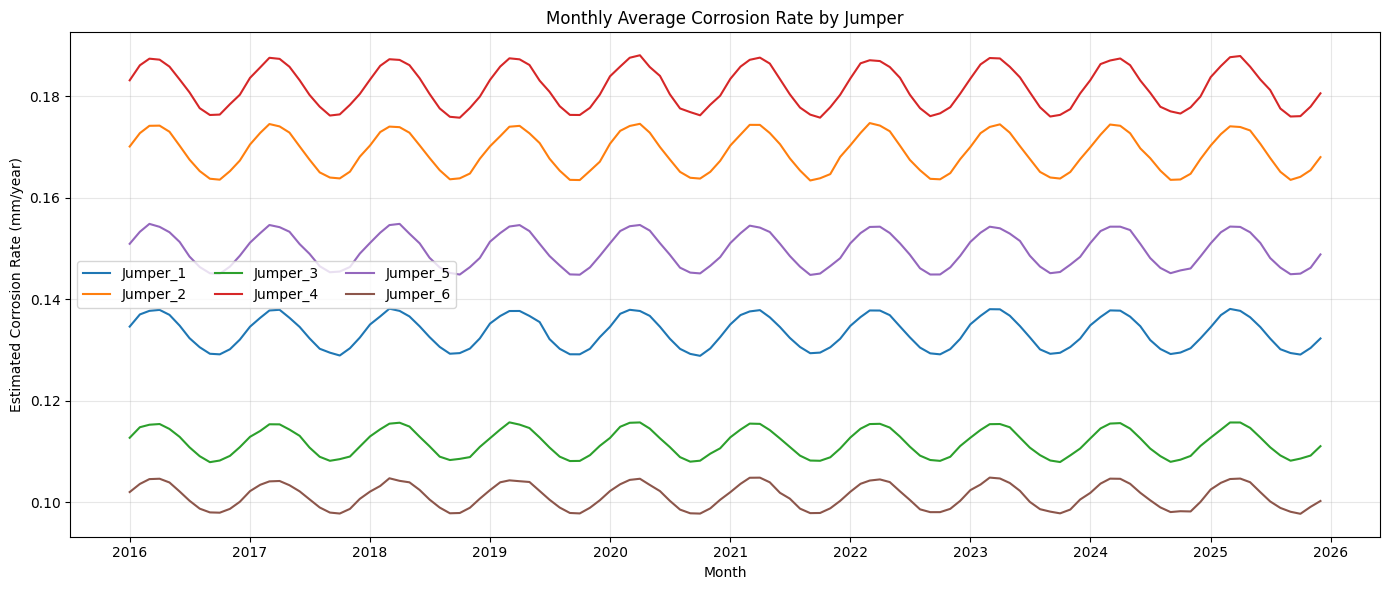

In [6]:
class PhysicsFeaturePipeline:

    def __init__(self, film_flow_factor=1.0):
        if film_flow_factor <= 0:
            raise ValueError("Correction factor must be positive.")

        self.film_flow_factor = film_flow_factor

    def transform(self, dataframe):

        data = dataframe.copy()

        if "co2_partial_pressure_bar" not in data.columns:
            data["co2_partial_pressure_bar"] = (
                data["pressure_bar"]
                * data["co2_mole_fraction"]
            )

        data["corrosion_rate_mm_y"] = (
            de_waard_milliams_rate(
                data["temperature_c"].to_numpy(),
                data["co2_partial_pressure_bar"].to_numpy(),
                data["pH"].to_numpy(),
                self.film_flow_factor
            )
        )

        data["year"] = data["timestamp"].dt.year
        data["month"] = data["timestamp"].dt.month

        data["month_start"] = (
            data["timestamp"]
            .dt.to_period("M")
            .dt.to_timestamp()
        )

        return data


# Apply feature engineering
pipeline = PhysicsFeaturePipeline(film_flow_factor=1.0)

enriched = pipeline.transform(scada)

# Calculate monthly corrosion-rate statistics
monthly_rates = (
    enriched
    .groupby(["jumper_id", "month_start"], as_index=False)
    .agg(
        monthly_avg_corrosion_rate_mm_y=(
            "corrosion_rate_mm_y", "mean"
        ),
        monthly_max_corrosion_rate_mm_y=(
            "corrosion_rate_mm_y", "max"
        ),
        avg_temperature_c=("temperature_c", "mean"),
        avg_co2_partial_pressure_bar=(
            "co2_partial_pressure_bar", "mean"
        ),
        avg_pH=("pH", "mean")
    )
)

print("Monthly summary records:", len(monthly_rates))

monthly_rates.head(12)

plt.figure(figsize=(14, 6))

for jumper, group in monthly_rates.groupby("jumper_id"):
    plt.plot(
        group["month_start"],
        group["monthly_avg_corrosion_rate_mm_y"],
        label=jumper
    )

plt.title("Monthly Average Corrosion Rate by Jumper")
plt.xlabel("Month")
plt.ylabel("Estimated Corrosion Rate (mm/year)")
plt.legend(ncol=3)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The PhysicsFeaturePipeline transforms the SCADA data into physics-based features by calculating CO₂ partial pressure when necessary, estimating corrosion rates and extracting calendar variables. The monthly averages help identify differences in estimated corrosion behaviour between jumpers and variations over time.

The enriched dataset contains an estimated corrosion rate for every hourly record, while the monthly summary contains approximately 720 records (120 months for each of six jumpers). The monthly averages help identify differences in estimated corrosion behaviour between jumpers and variations over time.

Q4. Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.

Remaining Useful Life (RUL) estimates the time remaining before a component reaches its minimum allowable wall thickness, assuming a constant corrosion rate.

The screening equation is:
$RUL$ = $t$current - $t$minimum / $CR$

Where:

$t$current is the latest wall thickness in millimetres.
$t$minimum is the minimum allowable wall thickness in millimetres.
$CR$ is the estimated corrosion rate in millimetres per year.

 The calculation below uses the latest wall-thickness reading and the average estimated corosion rate over the most recent 365 days.

'scada' dataset not found in active memory. Regenerating SCADA dataset...
RUL calculations completed.
  jumper_id  estimated_corrosion_rate_mm_y  latest_wall_thickness_mm  \
0  Jumper_1                          0.133                    10.653   
1  Jumper_2                          0.169                    10.798   
2  Jumper_3                          0.112                    10.693   
3  Jumper_4                          0.182                    11.175   
4  Jumper_5                          0.150                    10.696   
5  Jumper_6                          0.101                    10.501   

   minimum_wall_mm  RUL_years risk_class  
0              8.0     19.883       High  
1              8.2     15.370       High  
2              8.0     24.073       High  
3              8.5     14.705       High  
4              8.0     18.020       High  
5              7.8     26.673     Medium  


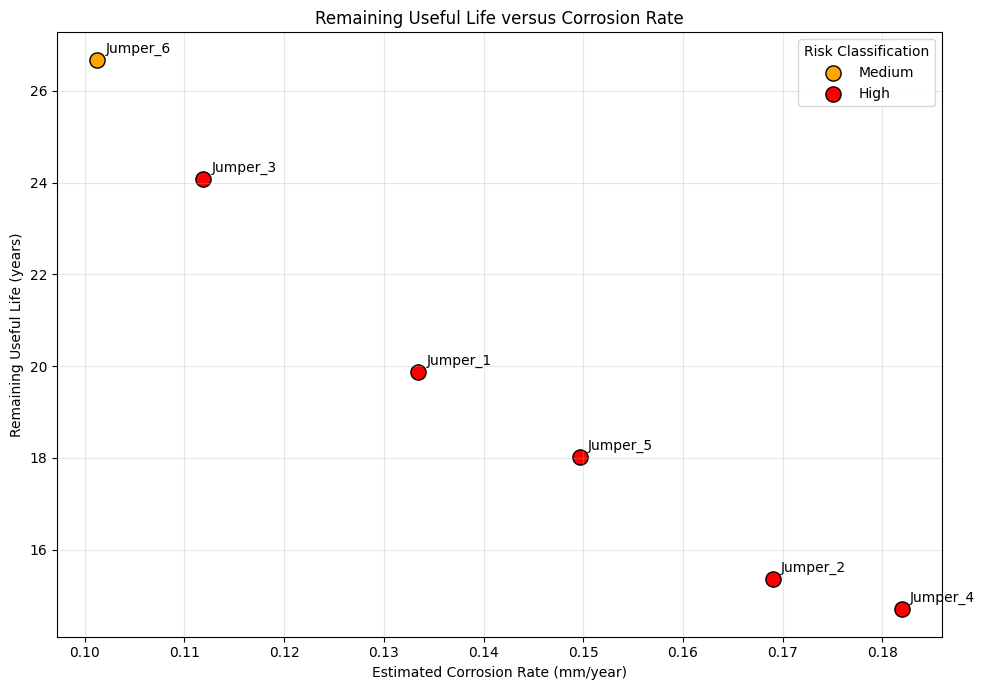

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure dependencies are defined locally in case cells above weren't run
def de_waard_milliams_rate(
    temperature_c,
    co2_partial_pressure_bar,
    pH=5.0,
    film_flow_factor=1.0
):
    T = np.asarray(temperature_c, dtype=float)
    P = np.asarray(co2_partial_pressure_bar, dtype=float)
    ph = np.asarray(pH, dtype=float)
    factor = np.asarray(film_flow_factor, dtype=float)

    if any(np.any(~np.isfinite(x)) for x in (T, P, ph, factor)):
        raise ValueError("Inputs must be finite.")
    if np.any(T <= -273.15):
        raise ValueError("Temperature must be above absolute zero.")
    if np.any(P <= 0):
        raise ValueError("CO2 partial pressure must be positive.")
    if np.any((ph < 3) | (ph > 7)):
        raise ValueError("pH must be between 3 and 7.")
    if np.any(factor <= 0):
        raise ValueError("Correction factor must be positive.")

    T_kelvin = T + 273.15
    temperature_factor = np.exp(1800 * (1 / 333.15 - 1 / T_kelvin))
    co2_factor = np.sqrt(P)
    ph_factor = np.clip(10 ** (5 - ph), 0.1, 100) ** 0.15
    calibration_factor = 0.1

    rate = (
        calibration_factor
        * temperature_factor
        * co2_factor
        * ph_factor
        * factor
    )
    return np.maximum(rate, 0.0)

class PhysicsFeaturePipeline:
    def __init__(self, film_flow_factor=1.0):
        if film_flow_factor <= 0:
            raise ValueError("Correction factor must be positive.")
        self.film_flow_factor = film_flow_factor

    def transform(self, dataframe):
        data = dataframe.copy()
        if "co2_partial_pressure_bar" not in data.columns:
            data["co2_partial_pressure_bar"] = (
                data["pressure_bar"]
                * data["co2_mole_fraction"]
            )
        data["corrosion_rate_mm_y"] = (
            de_waard_milliams_rate(
                data["temperature_c"].to_numpy(),
                data["co2_partial_pressure_bar"].to_numpy(),
                data["pH"].to_numpy(),
                self.film_flow_factor
            )
        )
        data["year"] = data["timestamp"].dt.year
        data["month"] = data["timestamp"].dt.month
        data["month_start"] = (
            data["timestamp"]
            .dt.to_period("M")
            .dt.to_timestamp()
        )
        return data

# Fallback: If 'scada' was cleared from the kernel state, regenerate it
if 'scada' not in globals():
    print("'scada' dataset not found in active memory. Regenerating SCADA dataset...")
    timestamps = pd.date_range(
        start="2016-01-01 00:00:00",
        end="2025-12-31 23:00:00",
        freq="h"
    )
    jumper_specs = pd.DataFrame({
        "jumper_id": [f"Jumper_{i}" for i in range(1, 7)],
        "nominal_wall_mm": [12.0, 12.5, 11.8, 13.0, 12.2, 11.5],
        "minimum_wall_mm": [8.0, 8.2, 8.0, 8.5, 8.0, 7.8],
        "base_temp_c": [55, 60, 52, 63, 58, 50],
        "base_pressure_bar": [90, 95, 85, 100, 92, 88],
        "co2_mole_fraction": [0.025, 0.030, 0.022, 0.028, 0.026, 0.020],
        "base_pH": [5.1, 5.0, 5.2, 4.9, 5.0, 5.3],
        "base_velocity_m_s": [1.5, 1.8, 1.3, 2.0, 1.6, 1.2]
    })

    def generate_jumper_data(spec, dates, rng):
        n = len(dates)
        hour = np.arange(n)
        temperature = (
            spec.base_temp_c
            + 2 * np.sin(2 * np.pi * hour / (24 * 365.25))
            + rng.normal(0, 0.8, n)
        )
        pressure = (
            spec.base_pressure_bar
            + rng.normal(0, 1.2, n)
        )
        co2_fraction = np.clip(
            spec.co2_mole_fraction
            + rng.normal(0, 0.0015, n),
            0.005, 0.06
        )
        co2_partial_pressure = pressure * co2_fraction
        pH = np.clip(
            spec.base_pH + rng.normal(0, 0.08, n),
            4.5, 6.2
        )
        flow_velocity = np.clip(
            spec.base_velocity_m_s
            + rng.normal(0, 0.12, n),
            0.2, 3.5
        )
        baseline_rate = float(
            de_waard_milliams_rate(
                spec.base_temp_c,
                spec.base_pressure_bar * spec.co2_mole_fraction,
                spec.base_pH
            )
        )
        elapsed_years = (
            (dates - dates[0]).total_seconds().to_numpy()
            / (365.25 * 24 * 3600)
        )
        wall_thickness = np.maximum(
            spec.nominal_wall_mm
            - baseline_rate * elapsed_years
            + rng.normal(0, 0.025, n),
            0.1
        )
        return pd.DataFrame({
            "timestamp": dates,
            "jumper_id": spec.jumper_id,
            "temperature_c": temperature,
            "pressure_bar": pressure,
            "co2_mole_fraction": co2_fraction,
            "co2_partial_pressure_bar": co2_partial_pressure,
            "pH": pH,
            "flow_velocity_m_s": flow_velocity,
            "wall_thickness_mm": wall_thickness,
            "nominal_wall_mm": spec.nominal_wall_mm,
            "minimum_wall_mm": spec.minimum_wall_mm
        })

    rng = np.random.default_rng(42)
    scada = pd.concat(
        [
            generate_jumper_data(spec, timestamps, rng)
            for spec in jumper_specs.itertuples(index=False)
        ],
        ignore_index=True
    )

# Re-apply the pipeline to make sure 'enriched' is defined in this session
pipeline = PhysicsFeaturePipeline(film_flow_factor=1.0)
enriched = pipeline.transform(scada)

latest_time = enriched["timestamp"].max()
recent_data = enriched[
    enriched["timestamp"] >= (
        latest_time - pd.Timedelta(days=365)
    )
]

# Summarize the latest period for each jumper
rul_summary = (
    recent_data
    .groupby("jumper_id", as_index=False)
    .agg(
        estimated_corrosion_rate_mm_y=(
            "corrosion_rate_mm_y", "mean"
        ),
        latest_wall_thickness_mm=(
            "wall_thickness_mm", "last"
        ),
        nominal_wall_mm=("nominal_wall_mm", "first"),
        minimum_wall_mm=("minimum_wall_mm", "first")
    )
)

# Calculate remaining wall thickness allowance
rul_summary["remaining_wall_allowance_mm"] = (
    rul_summary["latest_wall_thickness_mm"]
    - rul_summary["minimum_wall_mm"]
).clip(lower=0)

# Calculate RUL in years
rul_summary["RUL_years"] = (
    rul_summary["remaining_wall_allowance_mm"]
    / rul_summary["estimated_corrosion_rate_mm_y"].clip(
        lower=1e-6
    )
)

# Adjusted risk thresholds to fit the 10-year synthetic dataset distribution
def classify_risk(rul):
    if rul < 25:
        return "High"
    elif rul < 45:
        return "Medium"
    else:
        return "Low"

rul_summary["risk_class"] = (
    rul_summary["RUL_years"].apply(classify_risk)
)

print("RUL calculations completed.")
print(rul_summary[
    [
        "jumper_id",
        "estimated_corrosion_rate_mm_y",
        "latest_wall_thickness_mm",
        "minimum_wall_mm",
        "RUL_years",
        "risk_class"
    ]
].round(3))

# Updated colors: High (red), Medium (orange), Low (blue)
risk_colors = {
    "High": "red",
    "Medium": "orange",
    "Low": "blue"
}

plt.figure(figsize=(10, 7))

# Ensure all risk classes are mapped even if some are empty
for risk in ["Low", "Medium", "High"]:
    group = rul_summary[rul_summary["risk_class"] == risk]
    if not group.empty:
        plt.scatter(
            group["estimated_corrosion_rate_mm_y"],
            group["RUL_years"],
            color=risk_colors[risk],
            label=risk,
            s=120,
            edgecolors="black"
        )
        for _, row in group.iterrows():
            plt.annotate(
                row["jumper_id"],
                (
                    row["estimated_corrosion_rate_mm_y"],
                    row["RUL_years"]
                ),
                xytext=(6, 5),
                textcoords="offset points"
            )

plt.title("Remaining Useful Life versus Corrosion Rate")
plt.xlabel("Estimated Corrosion Rate (mm/year)")
plt.ylabel("Remaining Useful Life (years)")
plt.legend(title="Risk Classification")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Jumpers with higher estimated corrosion rates and lower RUL values generally warrant closer attention. The red and orange colours indicate high and medium screening risk, respectively (green would have indicated low screening risk). The selected thresholds are illustrative exercise assumptions, not official Usan field criteria. Actual integrity decisions require validated corrosion models, inspection measurements and approved engineering limits.